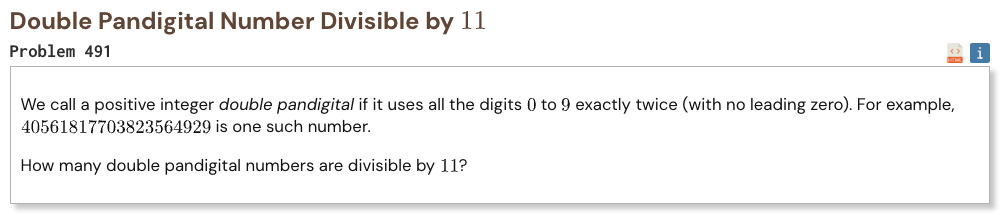

## Initial approach

- split the 20 positions into odd and even positions
- divisibility by 11 depends on the difference between the digit sums in these two groups
- choose how many copies of each digit go into the odd positions
- the even positions automatically receive the remaining copies
- keep only choices that satisfy the divisibility rule
- count the distinct arrangements of both groups with factorials
- subtract arrangements where zero appears as the first digit
- add all valid cases together

In [1]:
%%time

import itertools
import math

factorial = [math.factorial(i) for i in range(11)]

result = 0

for odd_counts in itertools.product(range(3), repeat=10):
    if sum(odd_counts) != 10:
        continue

    odd_sum = sum(
        digit * odd_counts[digit]
        for digit in range(10)
    )

    if (2 * odd_sum - 90) % 11 != 0:
        continue

    odd_arrangements = factorial[10]
    even_arrangements = factorial[10]

    for digit in range(10):
        odd_arrangements //= factorial[odd_counts[digit]]
        even_arrangements //= factorial[2 - odd_counts[digit]]

    if odd_counts[0] > 0:
        leading_zero = factorial[9]
        leading_zero //= factorial[odd_counts[0] - 1]

        for digit in range(1, 10):
            leading_zero //= factorial[odd_counts[digit]]

        odd_arrangements -= leading_zero

    result += odd_arrangements * even_arrangements

print("Result:", result)

Result: 194505988824000
CPU times: user 19.9 ms, sys: 141 μs, total: 20 ms
Wall time: 20.1 ms
